# single-load

In [1]:
%load_ext autoreload
%autoreload 2

%pip install -r requirements.txt
%pip install -e .
%pip install matplotlib

import selfmade.nb101 as nb101
import selfmade.nbcore as nbcore

records = r'.\datas\nasbench_full.tfrecord'
space = nb101.NASBench101Space()
evaluator = nb101.NASBench101Evaluator(records, space)

You should consider upgrading via the 'c:\Users\Admin\AppData\Local\Programs\Python\Python37\python.exe -m pip install --upgrade pip' command.


Obtaining file:///E:/coding/uit_bs/nuro_evo/nb-new
  Attempting uninstall: nasbench
    Found existing installation: nasbench 1.0
    Uninstalling nasbench-1.0:
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not install packages due to an EnvironmentError: [Errno 2] No such file or directory: 'c:\\users\\admin\\appdata\\local\\programs\\python\\python37\\lib\\site-packages\\nasbench.egg-link'

You should consider upgrading via the 'c:\Users\Admin\AppData\Local\Programs\Python\Python37\python.exe -m pip install --upgrade pip' command.


You should consider upgrading via the 'c:\Users\Admin\AppData\Local\Programs\Python\Python37\python.exe -m pip install --upgrade pip' command.





Loading dataset from file... This may take a few minutes...
Instructions for updating:
Use eager execution and: 
`tf.data.TFRecordDataset(path)`


KeyboardInterrupt: 

In [ ]:
from sklearn.ensemble import RandomForestRegressor
import secrets
import matplotlib.pyplot as plt
import pandas as pd

# main functions

In [ ]:
# Full vanilla (100 evals -> 10 pop, 10 iters)
def vanilla_run(loops, pop):
    pop.evolve_loop(total_gen=loops)
    return pop

In [ ]:
# Half vanilla, half guided (100 evals -> 10 pop, 5 val, 5 gui)
def guided_run(loops, pop):
    split = int(loops/2)
    print("Half vanilla")
    pop.evolve_loop(total_gen=split)

    rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=1)
    fi = nbcore.FeatureImportance(space)
    imp = fi.pipeline(pop.data, rf)

    gui = nbcore.Guidance(space, imp, pop.config)
    gui.sortNsplit()
    gui.calculate_guidance()

    print("Half guided")
    pop.evolve_loop(total_gen=split, guidance = gui)
    return pop

In [ ]:
def compare_run(pop : nbcore.Population, loops = 20):
    split = int(loops / 2)
    print("Common half")
    pop.evolve_loop(total_gen = split)
    
    fv_pop = pop.copy()
    sv_pop = pop.copy()
    
    print("Full vanilla")
    fv_pop.evolve_loop(total_gen = split)
    
    print("Half guided")
    rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=1)
    fi = nbcore.FeatureImportance(space)
    for _ in range(split):
        imp = fi.pipeline(sv_pop.data, rf)

        gui = nbcore.Guidance(space, imp, sv_pop.config)
        gui.sortNsplit()
        gui.calculate_guidance()
        sv_pop.guidance = gui
        sv_pop.evolve()
    
    return fv_pop, sv_pop

# test run

In [ ]:
pop_size = 100
total_gen = 20
# Set seed và population chung để tạo tính công bằng cho 2 lượt chạy khác nhau
nb101.set_seed(42)
share_pop = nbcore.Population(pop_size, space, evaluator)
share_pop.initialize()
vanilla = share_pop.copy()
guided = share_pop.copy()

Best performance: 0.9458132982254028
Recording generation 0
Finished recording


In [ ]:
# fv = guided_run(total_gen, vanilla)
# sv = vanilla_run(total_gen, guided)

fv, sv = compare_run(share_pop)

Common half
Generation 1 - Best performance: 0.9458132982254028
Recording generation 1
Finished recording
Generation 2 - Best performance: 0.9471153616905212
Recording generation 2
Finished recording
Generation 3 - Best performance: 0.9474158883094788
Recording generation 3
Finished recording
Generation 4 - Best performance: 0.9474158883094788
Recording generation 4
Finished recording
Generation 5 - Best performance: 0.9474158883094788
Recording generation 5
Finished recording
Generation 6 - Best performance: 0.9474158883094788
Recording generation 6
Finished recording
Generation 7 - Best performance: 0.9485176205635071
Recording generation 7
Finished recording
Generation 8 - Best performance: 0.9490184187889099
Recording generation 8
Finished recording
Generation 9 - Best performance: 0.9490184187889099
Recording generation 9
Finished recording
Generation 10 - Best performance: 0.9490184187889099
Recording generation 10
Finished recording
Full vanilla
Generation 11 - Best performance:

# plot on vanilla + guided and compare with full vanilla

In [ ]:
int_ticks = range(0, total_gen + 1, 2)

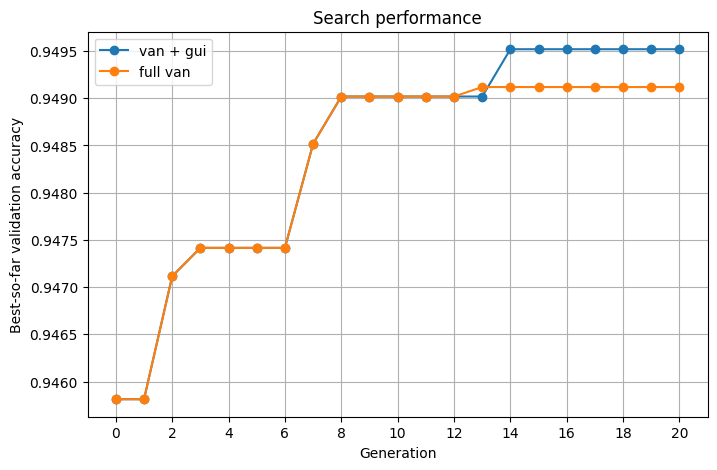

In [ ]:
hist = pd.DataFrame(sv.best_history)
hist2 = pd.DataFrame(fv.best_history)

plt.figure(figsize=(8, 5))
plt.plot(
    hist["generation"],
    hist["best_so_far"],
    marker="o"
)

plt.plot(
    hist2["generation"],
    hist2["best_so_far"],
    marker="o"
)

plt.xticks(int_ticks)
plt.xlabel("Generation")
plt.ylabel("Best-so-far validation accuracy")
plt.title("Search performance")
plt.legend(["van + gui", "full van"])
plt.grid(True)
plt.show()

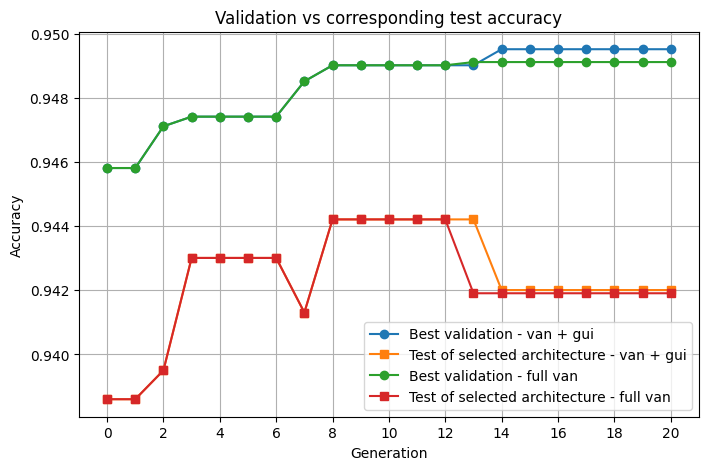

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    hist["generation"],
    hist["best_val"],
    marker="o",
    label="Best validation - van + gui"
)

plt.plot(
    hist["generation"],
    hist["best_test"],
    marker="s",
    label="Test of selected architecture - van + gui"
)

plt.plot(
    hist2["generation"],
    hist2["best_val"],
    marker="o",
    label="Best validation - full van"
)

plt.plot(
    hist2["generation"],
    hist2["best_test"],
    marker="s",
    label="Test of selected architecture - full van"
)

plt.xticks(int_ticks)
plt.xlabel("Generation")
plt.ylabel("Accuracy")
plt.title("Validation vs corresponding test accuracy")
plt.legend()
plt.grid(True)
plt.show()

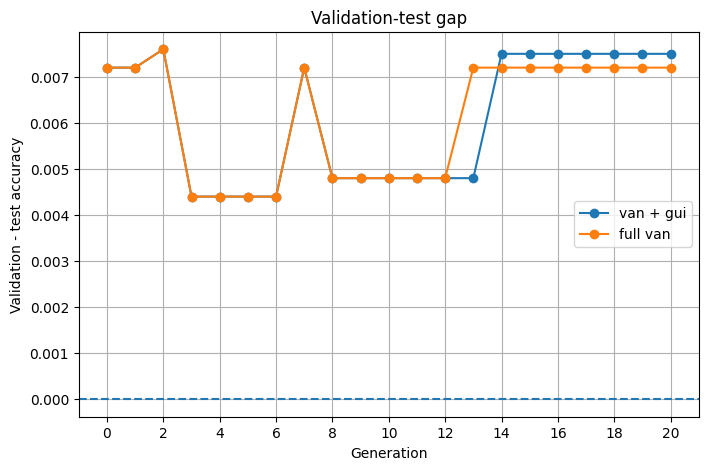

In [ ]:
hist["val_test_gap"] = (
    hist["best_val"] - hist["best_test"]
)

hist2["val_test_gap"] = (
    hist2["best_val"] - hist2["best_test"]
)

plt.figure(figsize=(8, 5))
plt.plot(
    hist["generation"],
    hist["val_test_gap"],
    marker="o"
)

plt.plot(
    hist2["generation"],
    hist2["val_test_gap"],
    marker="o"
)

plt.axhline(0, linestyle="--")

plt.xticks(int_ticks)
plt.xlabel("Generation")
plt.ylabel("Validation - test accuracy")
plt.title("Validation-test gap")
plt.legend(["van + gui", "full van"])
plt.grid(True)
plt.show()

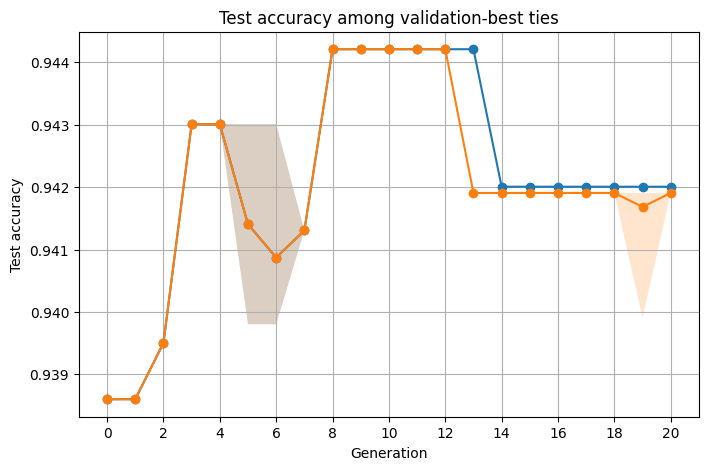

In [ ]:
plt.figure(figsize=(8, 5))

x = hist["generation"]
x2 = hist2["generation"]

plt.plot(
    x,
    hist["tied_test_mean"],
    marker="o",
    label="Mean test of validation ties - van + gui"
)

plt.fill_between(
    x,
    hist["tied_test_min"],
    hist["tied_test_max"],
    alpha=0.2,
    label="Test range among validation ties - van + gui"
)

plt.plot(
    x2,
    hist2["tied_test_mean"],
    marker="o",
    label="Mean test of validation ties - full van"
)

plt.fill_between(
    x2,
    hist2["tied_test_min"],
    hist2["tied_test_max"],
    alpha=0.2,
    label="Test range among validation ties - full van"
)

plt.xticks(int_ticks)
plt.xlabel("Generation")
plt.ylabel("Test accuracy")
plt.title("Test accuracy among validation-best ties")
# plt.legend(["van + gui", "full van"])
plt.grid(True)
plt.show()

In [ ]:
df = pd.DataFrame(sv.data)
df2 = pd.DataFrame(fv.data)

population_stats = (
    df.groupby("generation")["validation_accuracy"]
      .agg(["mean", "median", "min", "max"])
      .reset_index()
)

population_stats2 = (
    df2.groupby("generation")["validation_accuracy"]
      .agg(["mean", "median", "min", "max"])
      .reset_index()
)

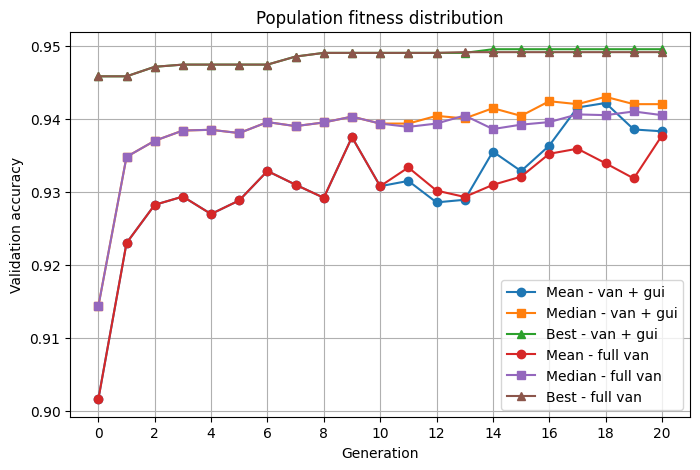

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    population_stats["generation"],
    population_stats["mean"],
    marker="o",
    label="Mean - van + gui"
)

plt.plot(
    population_stats["generation"],
    population_stats["median"],
    marker="s",
    label="Median - van + gui"
)

plt.plot(
    population_stats["generation"],
    population_stats["max"],
    marker="^",
    label="Best - van + gui"
)

plt.plot(
    population_stats2["generation"],
    population_stats2["mean"],
    marker="o",
    label="Mean - full van"
)

plt.plot(
    population_stats2["generation"],
    population_stats2["median"],
    marker="s",
    label="Median - full van"
)

plt.plot(
    population_stats2["generation"],
    population_stats2["max"],
    marker="^",
    label="Best - full van"
)

plt.xticks(int_ticks)
plt.xlabel("Generation")
plt.ylabel("Validation accuracy")
plt.title("Population fitness distribution")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
def genome_signature(rep):
    return (
        rep["code"],
        tuple(rep["operations"])
    )

In [ ]:
df["signature"] = df["representation"].apply(genome_signature)
df2["signature"] = df2["representation"].apply(genome_signature)

diversity = (
    df.groupby("generation")["signature"]
      .nunique()
      .reset_index(name="unique_architectures")
)

diversity2 = (
    df2.groupby("generation")["signature"]
      .nunique()
      .reset_index(name="unique_architectures")
)

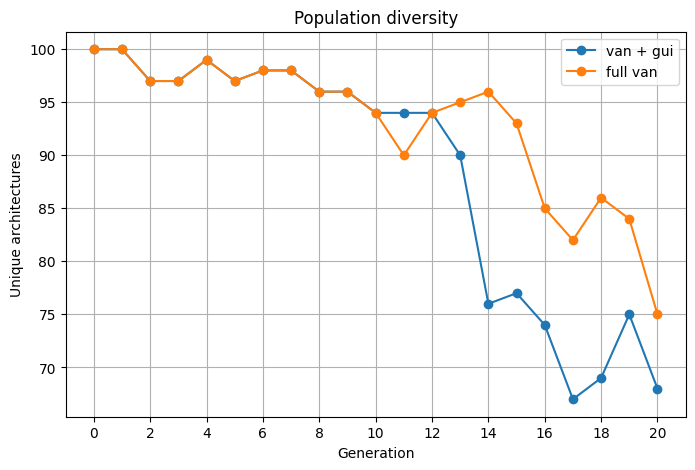

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    diversity["generation"],
    diversity["unique_architectures"],
    marker="o"
)

plt.plot(
    diversity2["generation"],
    diversity2["unique_architectures"],
    marker="o"
)

plt.xticks(int_ticks)
plt.xlabel("Generation")
plt.ylabel("Unique architectures")
plt.title("Population diversity")
plt.legend(["van + gui", "full van"])
plt.grid(True)
plt.show()

# seed loop

In [ ]:
def loopy_loop(n_runs, size, loops):
    fv_seed = []
    sv_seed = []
    seeds = []

    for run in range(n_runs):
        s = secrets.randbits(32)
        seeds.append(s)

        print(f"Running {run + 1}/{n_runs} | seed = {s}")

        nb101.set_seed(s)
        com_pop = nbcore.Population(size, space, evaluator)
        com_pop.initialize()
        # van = com_pop.copy()
        # gui = com_pop.copy()

        # fv = vanilla_run(loops, van)
        # sv = guided_run(loops, gui)

        fv, sv = compare_run(com_pop, loops=loops)
        
        fv_seed.append(fv)
        sv_seed.append(sv)

    return fv_seed, sv_seed, seeds

In [ ]:
runs = 40
pop = 100
evo = 20
fv, sv, seeds = loopy_loop(runs, pop, evo)
# fv, sv, seeds = loopy_loop(20, pop_size * 2, 50)

Running 1/40 | seed = 889645521
Best performance: 0.9420071840286255
Recording generation 0
Finished recording
Common half
Generation 1 - Best performance: 0.9420071840286255
Recording generation 1
Finished recording
Generation 2 - Best performance: 0.9471153616905212
Recording generation 2
Finished recording
Generation 3 - Best performance: 0.9474158883094788
Recording generation 3
Finished recording
Generation 4 - Best performance: 0.9474158883094788
Recording generation 4
Finished recording
Generation 5 - Best performance: 0.9474158883094788
Recording generation 5
Finished recording
Generation 6 - Best performance: 0.9495192170143127
Recording generation 6
Finished recording
Generation 7 - Best performance: 0.9495192170143127
Recording generation 7
Finished recording
Generation 8 - Best performance: 0.9495192170143127
Recording generation 8
Finished recording
Generation 9 - Best performance: 0.9495192170143127
Recording generation 9
Finished recording
Generation 10 - Best performanc

In [ ]:
def make_history_df(runs, seeds, method):
    rows = []

    for pop, seed in zip(runs, seeds):
        for h in pop.best_history:
            rows.append({
                "seed": seed,
                "method": method,
                "generation": h["generation"],
                "best_val": h["best_val"],
                "best_so_far": h["best_so_far"],
                "best_test": h["best_test"],
                "tied_test_min": h["tied_test_min"],
                "tied_test_max": h["tied_test_max"],
                "tied_test_mean": h["tied_test_mean"],
                "num_tied": h["num_tied"],
            })

    return pd.DataFrame(rows)

In [ ]:
vanilla_df = make_history_df(fv,seeds,"Vanilla")
guided_df = make_history_df(sv,seeds,"Guided")

history_df = pd.concat([vanilla_df, guided_df],ignore_index=True)

In [ ]:
import numpy as np

def summarize(df):
    summary = (
        df.groupby(["method", "generation"])["best_so_far"]
        .agg(["mean", "std", "count"])
        .reset_index()
    )

    summary["sem"] = (
        summary["std"] /
        np.sqrt(summary["count"])
    )

    summary["ci95"] = 1.96 * summary["sem"]

    return summary

In [ ]:
ticks = range(0, evo + 1, 2)

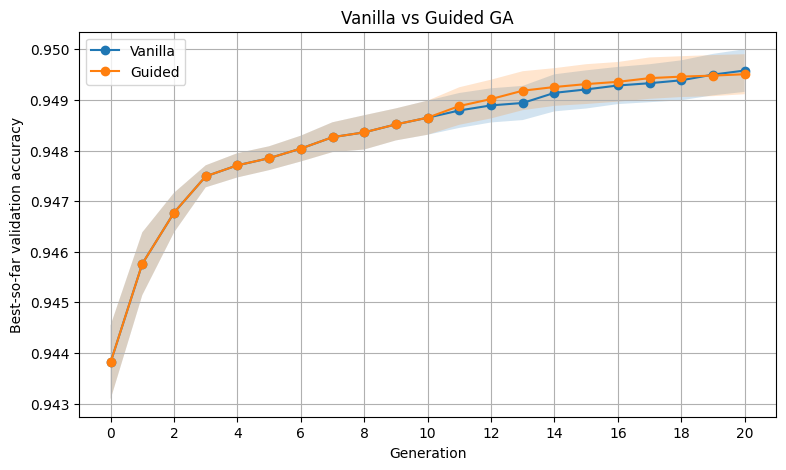

In [ ]:
summary = summarize(history_df)

plt.figure(figsize=(9, 5))

for method in ["Vanilla", "Guided"]:
    d = summary[summary["method"] == method]

    plt.plot(
        d["generation"],
        d["mean"],
        marker="o",
        label=method
    )

    plt.fill_between(
        d["generation"],
        d["mean"] - d["ci95"],
        d["mean"] + d["ci95"],
        alpha=0.2
    )

plt.xticks(ticks)
plt.xlabel("Generation")
plt.ylabel("Best-so-far validation accuracy")
plt.title("Vanilla vs Guided GA")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
def final_results(df):
    final = (
        df.sort_values("generation")
        .groupby(["seed", "method"])
        .tail(1)
    )

    return final

In [ ]:
final = final_results(history_df)

pivot = final.pivot(
    index="seed",
    columns="method",
    values="best_so_far"
)

pivot["improvement"] = (
    pivot["Guided"] - pivot["Vanilla"]
)

print(pivot)

method        Guided   Vanilla  improvement
seed                                       
16416791    0.951823  0.951823     0.000000
222025897   0.949519  0.949018     0.000501
314435748   0.947216  0.947216     0.000000
379141557   0.951823  0.951823     0.000000
569638443   0.949119  0.949519    -0.000401
606085846   0.949519  0.949119     0.000401
609592934   0.949519  0.949519     0.000000
649846273   0.951823  0.951823     0.000000
768019697   0.949519  0.949519     0.000000
889645521   0.949519  0.949519     0.000000
926301410   0.948117  0.947216     0.000901
967386766   0.951823  0.950321     0.001502
1114129387  0.949519  0.949119     0.000401
1223545081  0.948117  0.948518    -0.000401
1586363485  0.947216  0.947216     0.000000
1678015198  0.948518  0.951823    -0.003305
1849514599  0.948117  0.949018    -0.000901
1852037955  0.948518  0.948518     0.000000
1854419088  0.949519  0.949519     0.000000
1858495131  0.949519  0.949519     0.000000
1866433332  0.949519  0.949018  

In [ ]:
import numpy as np
from scipy.stats import wilcoxon

# Compare test accuracy of the selected architecture
test_pivot = final.pivot(
    index="seed",
    columns="method",
    values="best_test"
).dropna()

diff = test_pivot["Guided"] - test_pivot["Vanilla"]

print("Mean test accuracy:")
print(test_pivot[["Vanilla", "Guided"]].mean())

print("\nPaired test-accuracy differences (Guided - Vanilla):")
print("Mean:", diff.mean())
print("Median:", diff.median())
print("Wins:", (diff > 0).sum())
print("Ties:", (diff == 0).sum())
print("Losses:", (diff < 0).sum())

non_ties = diff[diff != 0]
if len(non_ties) > 0:
    print(
        "Wilcoxon p-value:",
        wilcoxon(non_ties).pvalue
    )

# Bootstrap confidence interval for the mean paired difference
rng = np.random.default_rng(42)
d = diff.to_numpy()
boot_means = np.array([
    rng.choice(d, size=len(d), replace=True).mean()
    for _ in range(20000)
])

print(
    "95% bootstrap CI:",
    np.quantile(boot_means, [0.025, 0.975])
)


Mean test accuracy:
method
Vanilla    0.941832
Guided     0.942105
dtype: float64

Paired test-accuracy differences (Guided - Vanilla):
Mean: 0.0002729371190071106
Median: 0.0
Wins: 10
Ties: 17
Losses: 13
Wilcoxon p-value: 0.8229274749755859
95% bootstrap CI: [-0.0003331   0.00092405]


In [ ]:
pivot["good"] = (pivot["improvement"] >= 0).astype(int)
pivot["good"].value_counts()

1    29
0    11
Name: good, dtype: int64

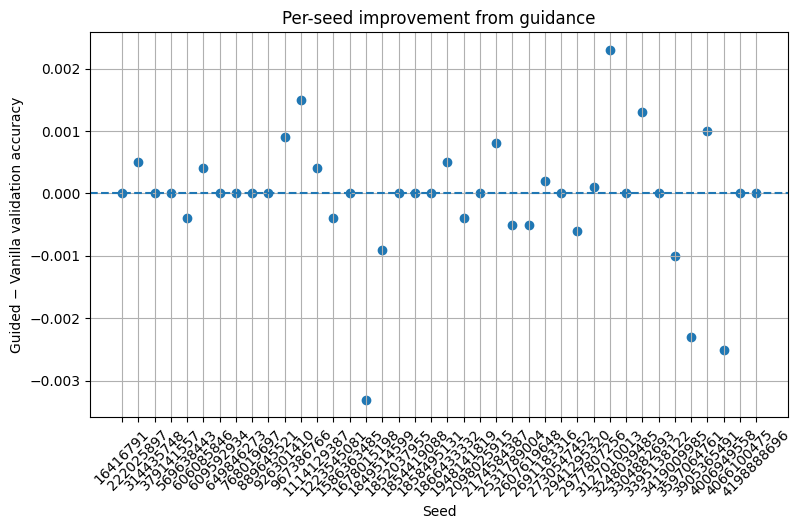

In [ ]:
plt.figure(figsize=(9, 5))

x = np.arange(len(pivot))

plt.axhline(
    0,
    linestyle="--"
)

plt.scatter(
    x,
    pivot["improvement"]
)

plt.xticks(
    x,
    [str(s) for s in pivot.index],
    rotation=45
)

plt.xlabel("Seed")
plt.ylabel("Guided − Vanilla validation accuracy")
plt.title("Per-seed improvement from guidance")
plt.grid(True)
plt.show()

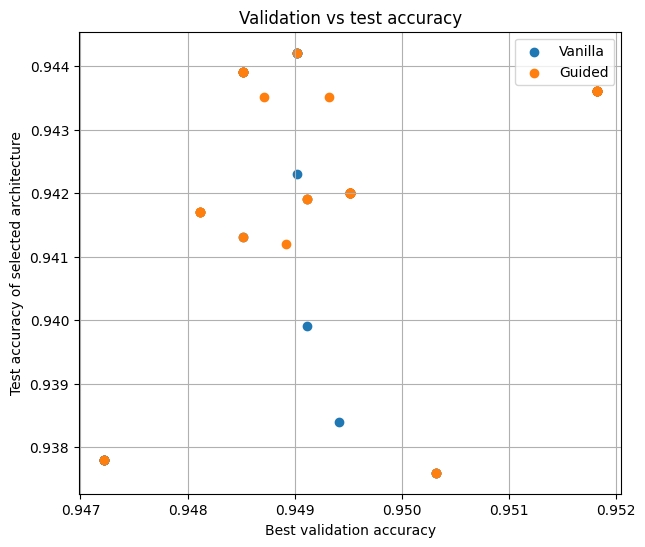

In [ ]:
final_val = final.copy()

plt.figure(figsize=(7, 6))

for method in ["Vanilla", "Guided"]:
    d = final_val[final_val["method"] == method]

    plt.scatter(
        d["best_so_far"],
        d["best_test"],
        label=method
    )

plt.xlabel("Best validation accuracy")
plt.ylabel("Test accuracy of selected architecture")
plt.title("Validation vs test accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
final_val["val_test_gap"] = (
    final_val["best_so_far"]
    - final_val["best_test"]
)

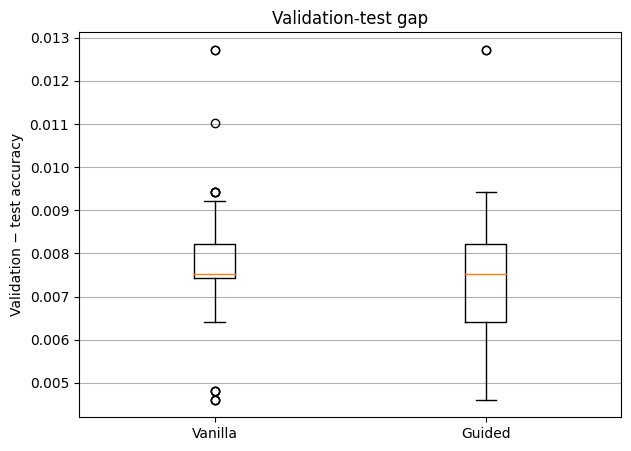

In [ ]:
plt.figure(figsize=(7, 5))

groups = [
    final_val[
        final_val["method"] == "Vanilla"
    ]["val_test_gap"],

    final_val[
        final_val["method"] == "Guided"
    ]["val_test_gap"]
]

plt.boxplot(
    groups,
    labels=["Vanilla", "Guided"]
)

plt.ylabel("Validation − test accuracy")
plt.title("Validation-test gap")
plt.grid(True, axis="y")
plt.show()